[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch07_yolo.ipynb)

# 7장 객체 검출 — YOLO11 커스텀 학습 · 실습 노트북
『보고, 읽고, 설명하는 딥러닝 — Colab에서 직접 만들며 배우는 딥러닝 응용』

7.5절 실습입니다. 수족관 사진 638장(7개 범주)으로 YOLO11s를 학습하고, 검증·테스트 데이터로 평가한 뒤 새 사진에서 물체를 찾아봅니다.
1. ultralytics 패키지 설치
2. 데이터 내려받기와 경로 설정(data.yaml)
3. 학습(`model.train`)
4. 결과 확인과 평가(`model.val`)
5. 검출(`model.predict`)

> **반드시 GPU 런타임**에서 실행하세요. 메뉴 [런타임] → [런타임 유형 변경]에서 **T4 GPU**를 고릅니다. 학습은 T4에서 약 6~7분 걸립니다.

데이터: Aquarium Dataset (Roboflow, CC BY 4.0) — https://public.roboflow.com/object-detection/aquarium
코드: Ultralytics YOLO (AGPL-3.0) — https://github.com/ultralytics/ultralytics

## 1. 설치

In [1]:
# YOLO11을 담은 ultralytics 패키지를 설치한다.
!pip install -q ultralytics
import ultralytics
# 파이썬·파이토치 버전과 GPU를 확인한다.
ultralytics.checks()

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.6/112.6 GB disk)


In [2]:
import os, glob, shutil, yaml
from collections import Counter
from IPython.display import Image, display
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from ultralytics import YOLO

## 2. 데이터 내려받기

In [3]:
# content 아래에 aquarium 디렉토리를 만들고 이동한다.
%mkdir -p /content/aquarium
%cd /content/aquarium
# 해당 주소에 요청을 보내 사진과 라벨을 내려받는다.
!curl -L "https://public.roboflow.com/ds/81nVUCrZxO?key=CWgQxO2lQs" > roboflow.zip; unzip -q roboflow.zip; rm roboflow.zip
%cd /content

/content/aquarium
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   910  100   910    0     0   1107      0 --:--:-- --:--:-- --:--:--  1108
100 66.9M  100 66.9M    0     0  9876k      0  0:00:06  0:00:06 --:--:-- 16.0M
/content


In [4]:
# glob -> 해당 경로의 파일을 리스트로 만든다.
train_img_list = glob.glob('/content/aquarium/train/images/*.jpg')
test_img_list = glob.glob('/content/aquarium/test/images/*.jpg')
valid_img_list = glob.glob('/content/aquarium/valid/images/*.jpg')
# train, test, valid의 수
print(len(train_img_list), len(test_img_list), len(valid_img_list))

448 63 127


### 라벨 파일 들여다보기
YOLO 형식의 라벨은 사진 한 장마다 텍스트 파일 하나입니다. 한 줄이 물체 하나이고, `범주 번호, 상자 중심 x, 중심 y, 너비, 높이`를 사진 크기에 대한 비율(0~1)로 적습니다.

In [5]:
label_file = sorted(glob.glob('/content/aquarium/train/labels/*.txt'))[0]
print(label_file)
print(open(label_file).read())

/content/aquarium/train/labels/IMG_2274_jpeg_jpg.rf.2f319e949748145fb22dcb52bb325a0c.txt
0 0.2734375 0.509765625 0.33984375 0.146484375
0 0.875 0.640625 0.24739583333333334 0.1259765625
0 0.65625 0.310546875 0.203125 0.109375
0 0.1640625 0.330078125 0.328125 0.109375
0 0.5390625 0.443359375 0.28515625 0.1044921875
0 0.453125 0.212890625 0.35546875 0.099609375
0 0.5143229166666666 0.2890625 0.2591145833333333 0.0986328125
0 0.24348958333333334 0.794921875 0.2643229166666667 0.09765625
0 0.7018229166666666 0.091796875 0.3489583333333333 0.0966796875
0 0.43359375 0.7783203125 0.3216145833333333 0.0927734375
0 0.8684895833333334 0.16796875 0.26171875 0.091796875
0 0.85546875 0.83984375 0.2864583333333333 0.087890625
0 0.8502604166666666 0.4931640625 0.2981770833333333 0.0849609375
0 0.15234375 0.6787109375 0.2955729166666667 0.08203125
0 0.734375 0.69140625 0.24739583333333334 0.0771484375
0 0.8997395833333334 0.3916015625 0.19921875 0.076171875
0 0.048828125 0.927734375 0.09765625 0.07617

`with open(파일 경로, 모드) as 파일 객체:` 구문은 파일을 열고, 구문이 끝나면 자동으로 닫아 줍니다.
`yaml.safe_load`는 YAML 파일을 파이썬 딕셔너리로 바꿉니다.

In [6]:
# data.yaml의 경로를 저장
data_yaml = '/content/aquarium/data.yaml'
# data.yaml 파일 정보를 확인
with open(data_yaml) as f:
  film = yaml.safe_load(f)
display(film)

{'train': '../train/images',
 'val': '../valid/images',
 'nc': 7,
 'names': ['fish',
  'jellyfish',
  'penguin',
  'puffin',
  'shark',
  'starfish',
  'stingray']}

In [7]:
# 데이터 폴더와 train, valid, test 사진의 경로를 바꿔준다.
film['path'] = '/content/aquarium'
film['train'] = 'train/images'
film['val'] = 'valid/images'
film['test'] = 'test/images'
# 파이썬 데이터를 yaml 형태로 저장한다.
with open(data_yaml, 'w') as f:
  yaml.dump(film, f)
print('클래스 수:', film['nc'], film['names'])

클래스 수: 7 ['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']


In [8]:
# 잘못된 라벨이 있는지 확인
def find_files_with_invalid_labels(label_dir, valid_labels):
    """YOLO 형식의 유효하지 않은 레이블이 포함된 파일을 찾습니다."""
    invalid_files = []
    for label_file in glob.glob(os.path.join(label_dir, '*.txt')):
        with open(label_file, 'r') as f:
            for line in f:
                label = int(line.split()[0])  # 첫 번째 요소를 레이블로 추출
                if label not in valid_labels:
                    invalid_files.append(label_file)
                    break  # 유효하지 않은 레이블을 찾은 후 이 파일 검색을 중지합니다.
    return invalid_files

invalid_files = find_files_with_invalid_labels('/content/aquarium/train/labels', list(range(7)))
if invalid_files:
    print("유효하지 않은 레이블이 포함된 파일:", invalid_files)
else:
    print("유효하지 않은 레이블이 포함된 파일을 찾을 수 없습니다.")

유효하지 않은 레이블이 포함된 파일을 찾을 수 없습니다.


## 3. 학습
- `YOLO('yolo11s.pt')`: COCO(80개 범주)로 사전학습된 YOLO11s를 불러옵니다. 범주 수는 data.yaml을 보고 7개로 자동으로 바뀝니다.
- `data`: 데이터 설정(yaml) 파일, `epochs`: 에포크 수, `imgsz`: 입력 이미지 크기, `batch`: 배치 크기
- `name`: 결과 폴더 이름(`runs/detect/aquarium_results`)

In [9]:
%%time
# 학습 시간을 잰다.
model = YOLO('yolo11s.pt')
results = model.train(data=data_yaml, epochs=30, imgsz=768, batch=32, name='aquarium_results')

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aquarium/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=aquarium_results, nbs=64, nms=None, opset=None, optimize=False

## 4. 결과 확인과 평가

In [10]:
# 결과 폴더를 확인
run_dir = '/content/runs/detect/aquarium_results'
print(sorted(os.listdir(run_dir)))

['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'args.yaml', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'train_batch280.jpg', 'train_batch281.jpg', 'train_batch282.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'weights']


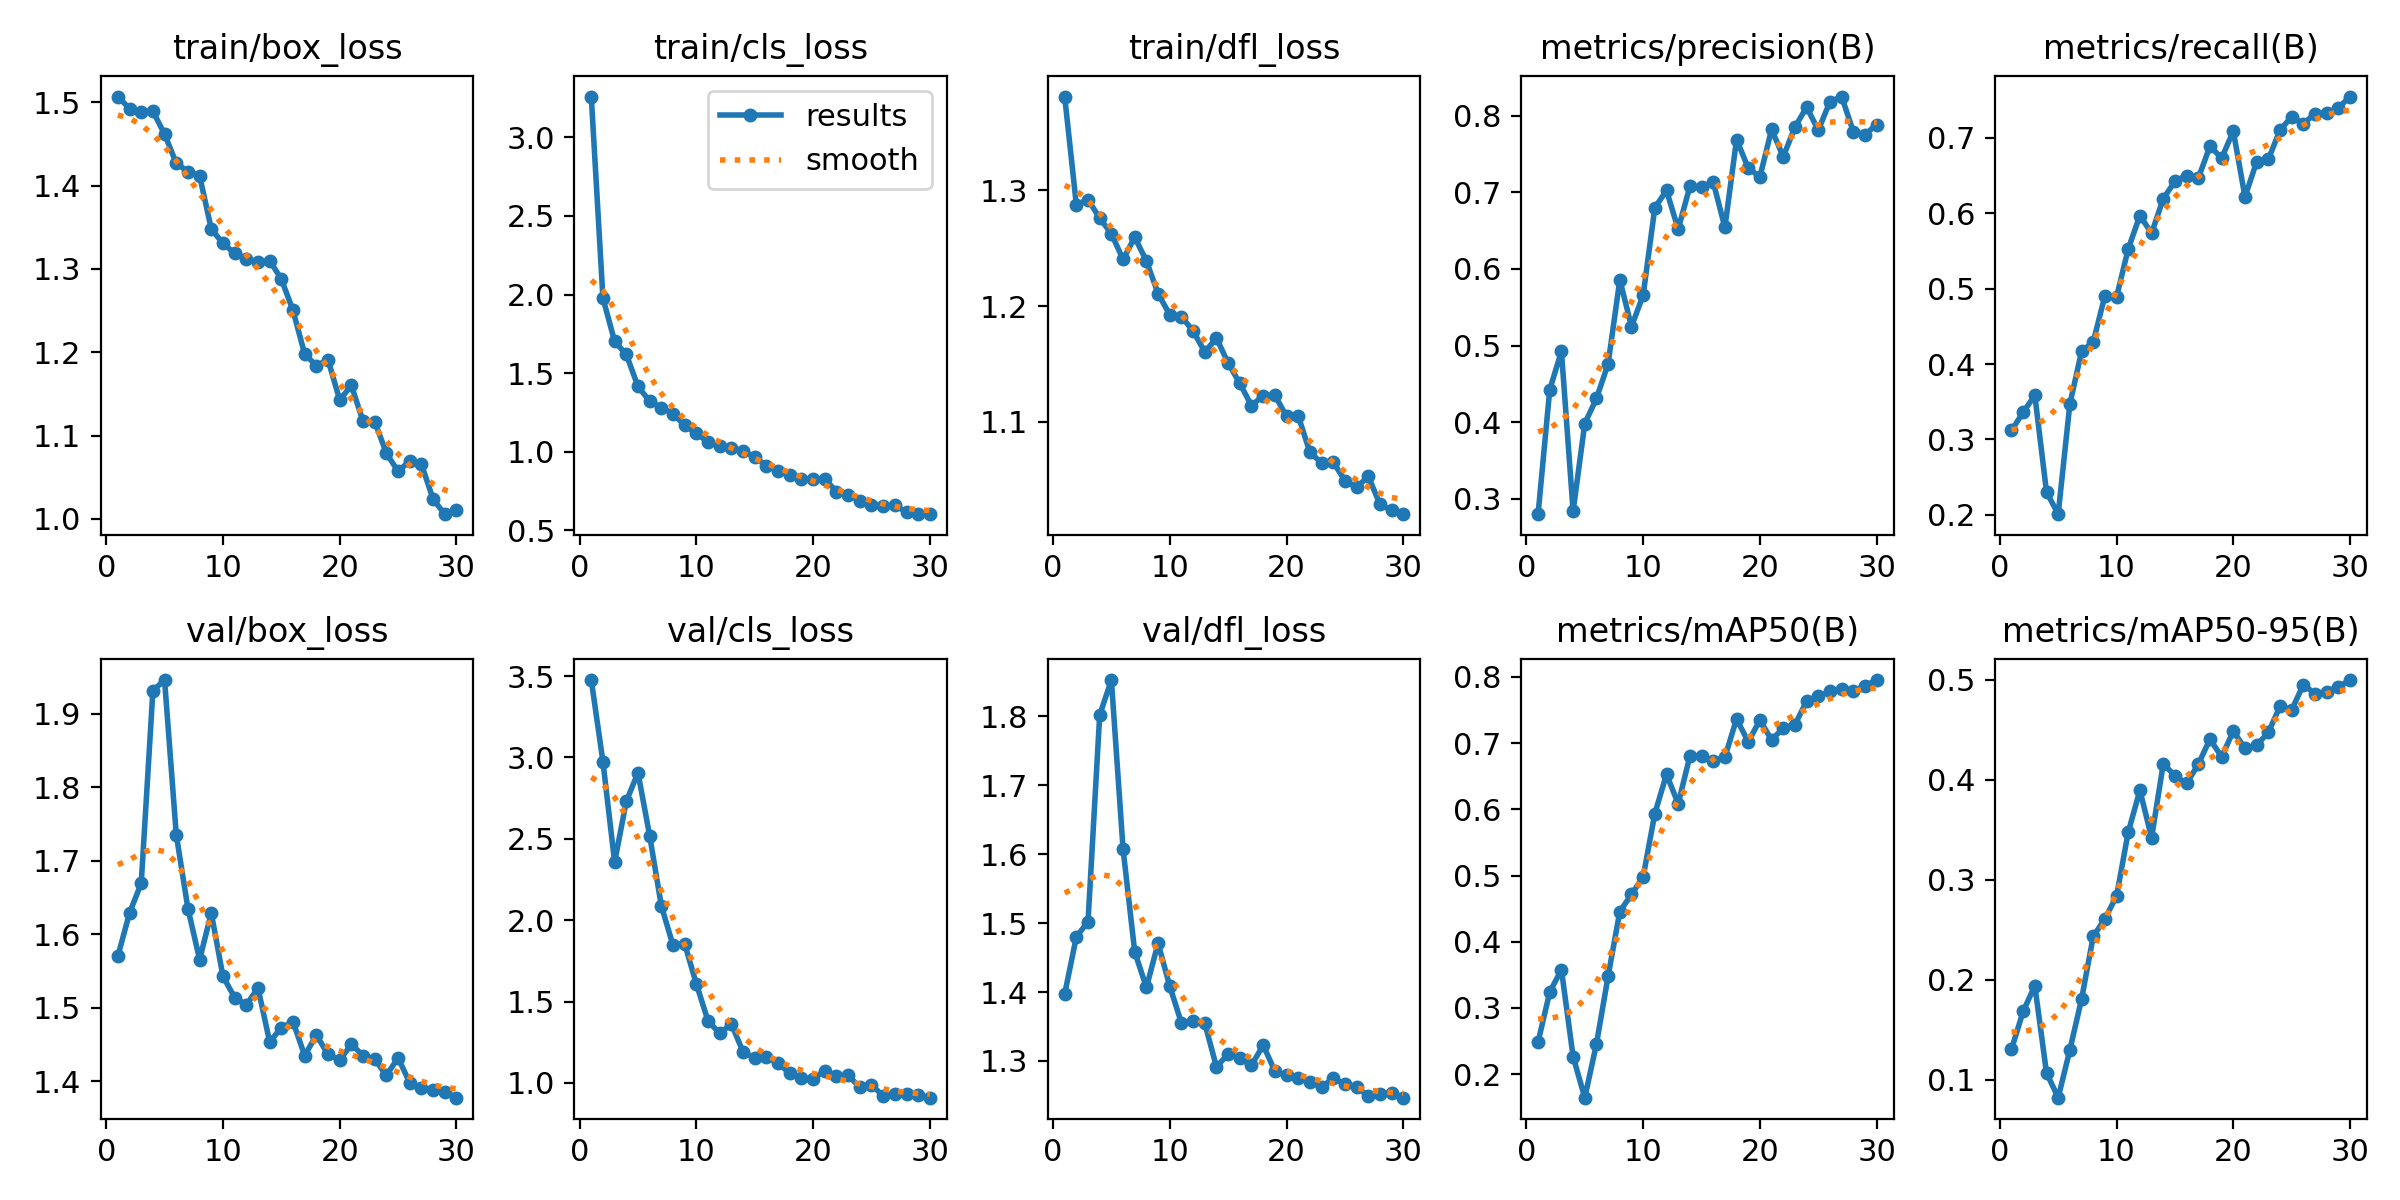

In [11]:
# 에포크별 손실과 mAP 그래프
Image(filename=f'{run_dir}/results.png', width=1000)

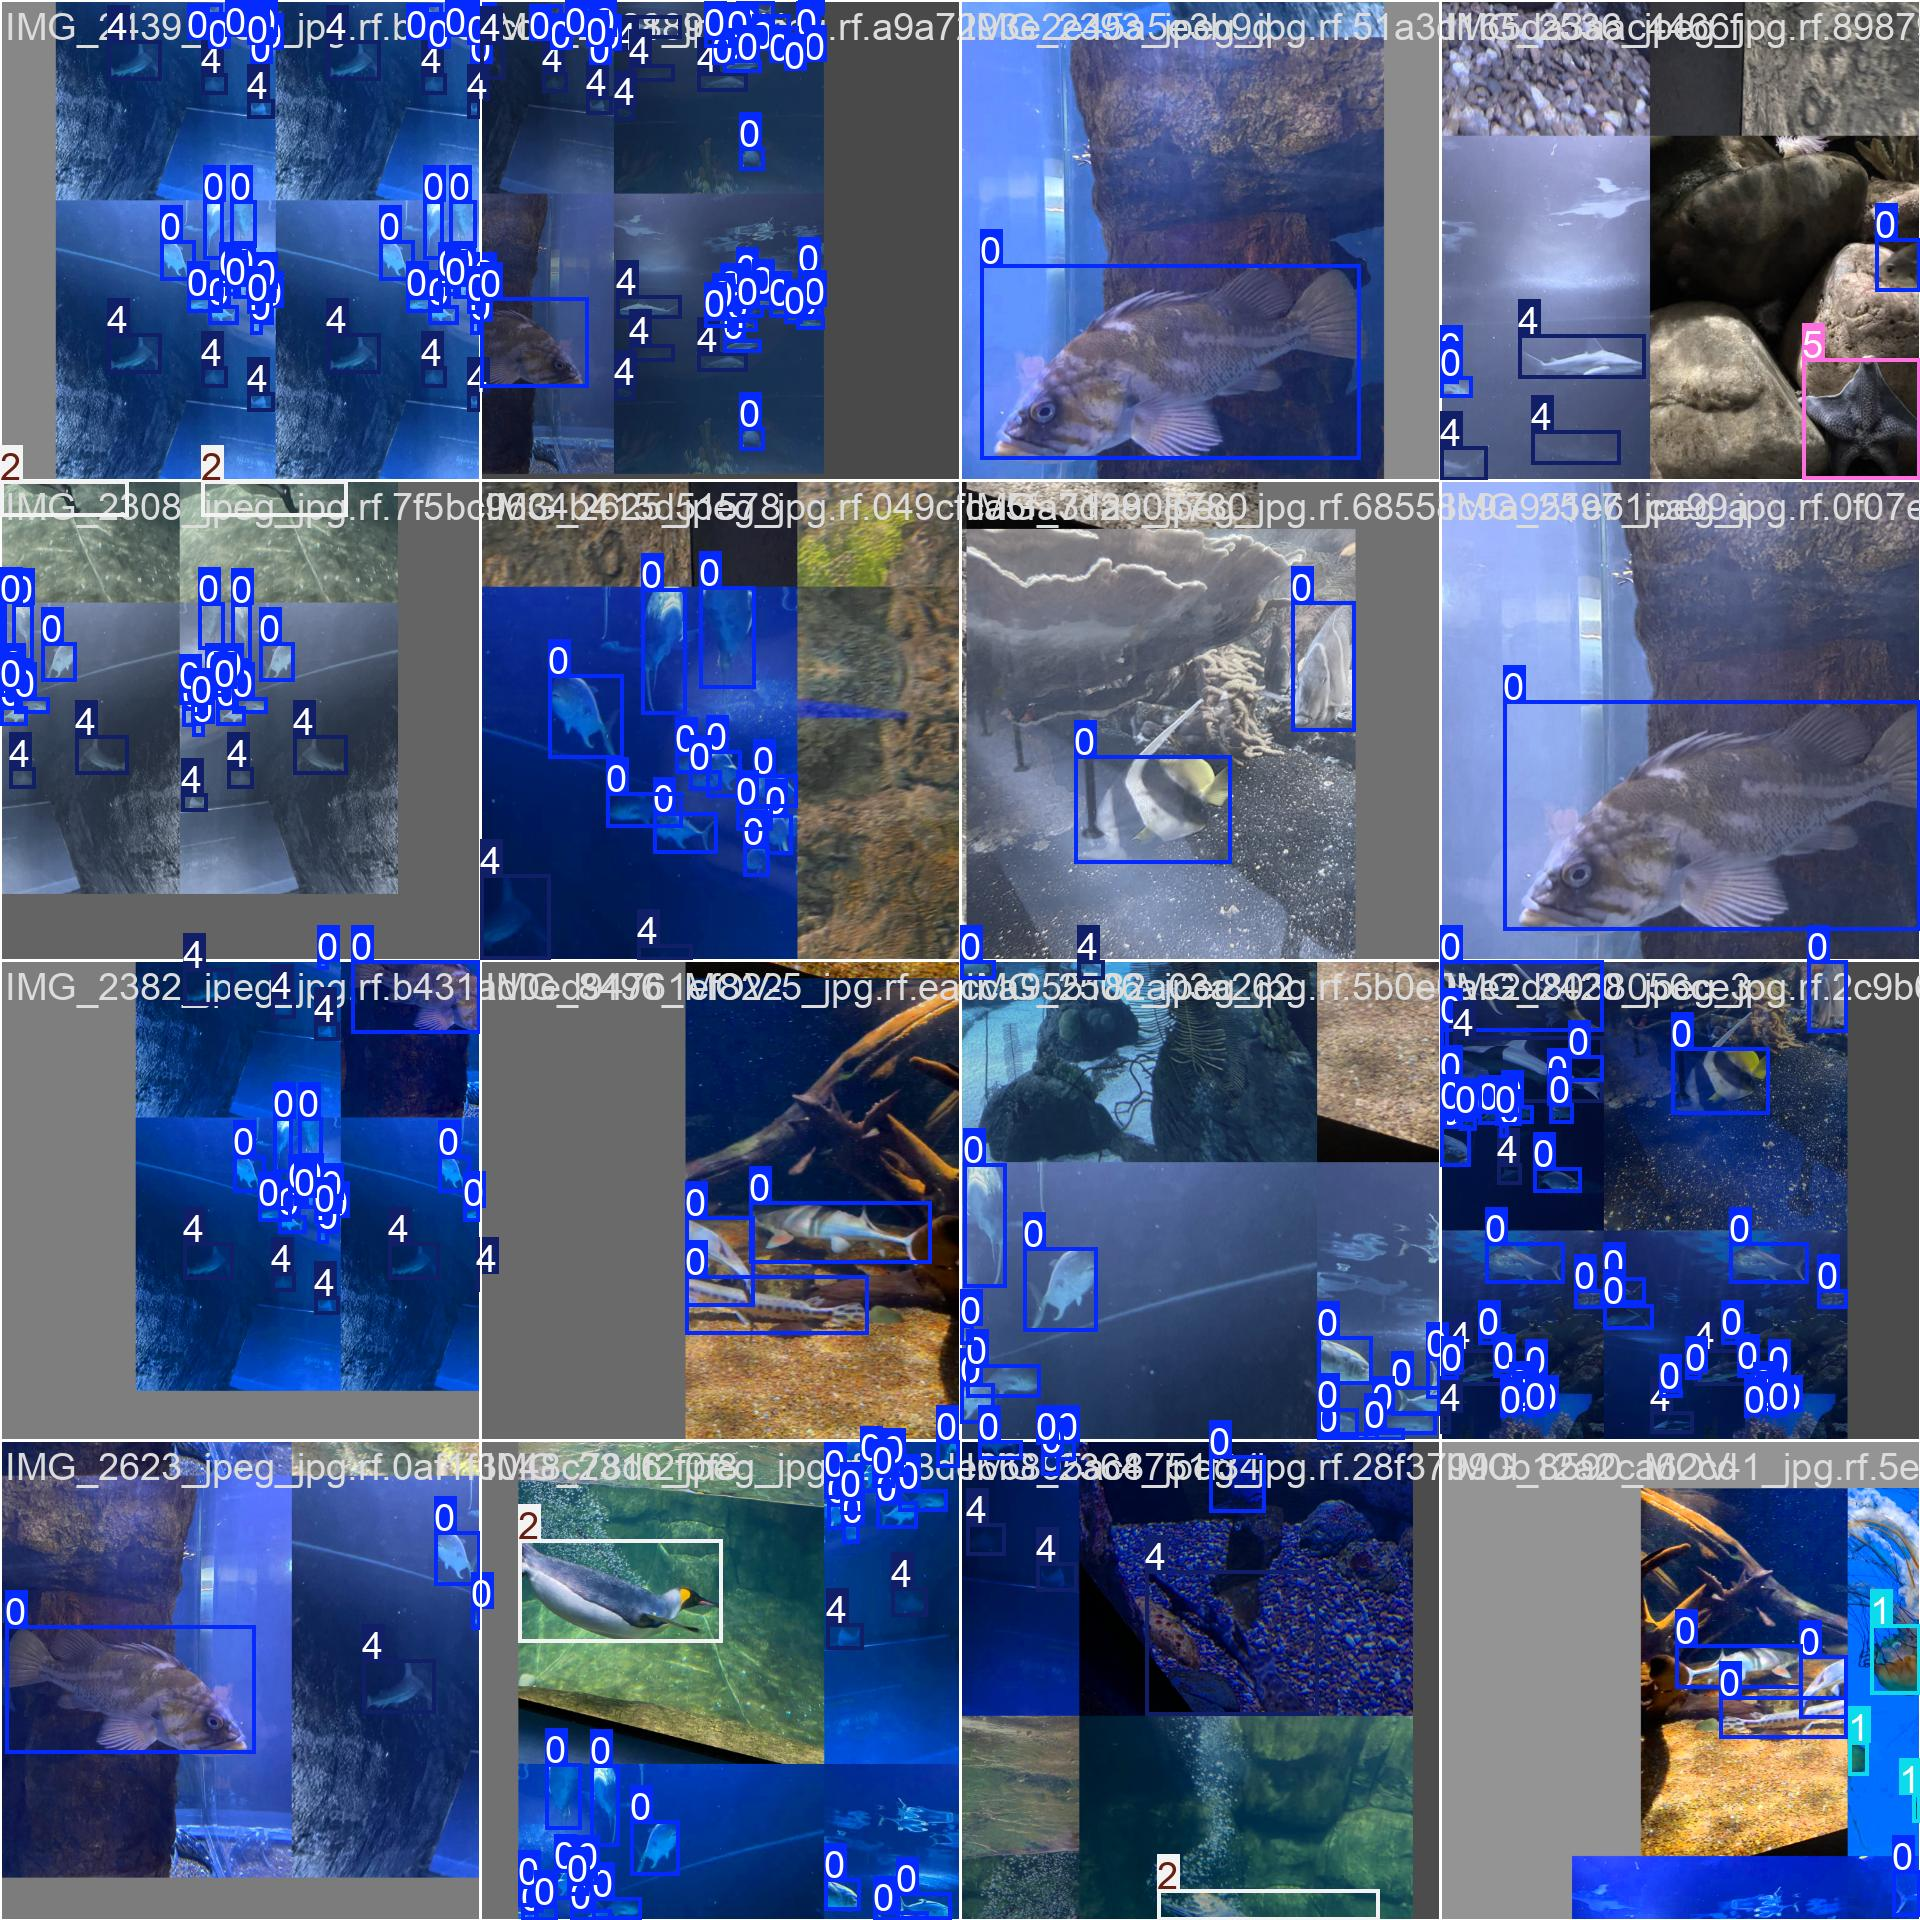

In [12]:
# train에 사용된 이미지들(모자이크 증강)
Image(filename=f'{run_dir}/train_batch0.jpg', width=1000)

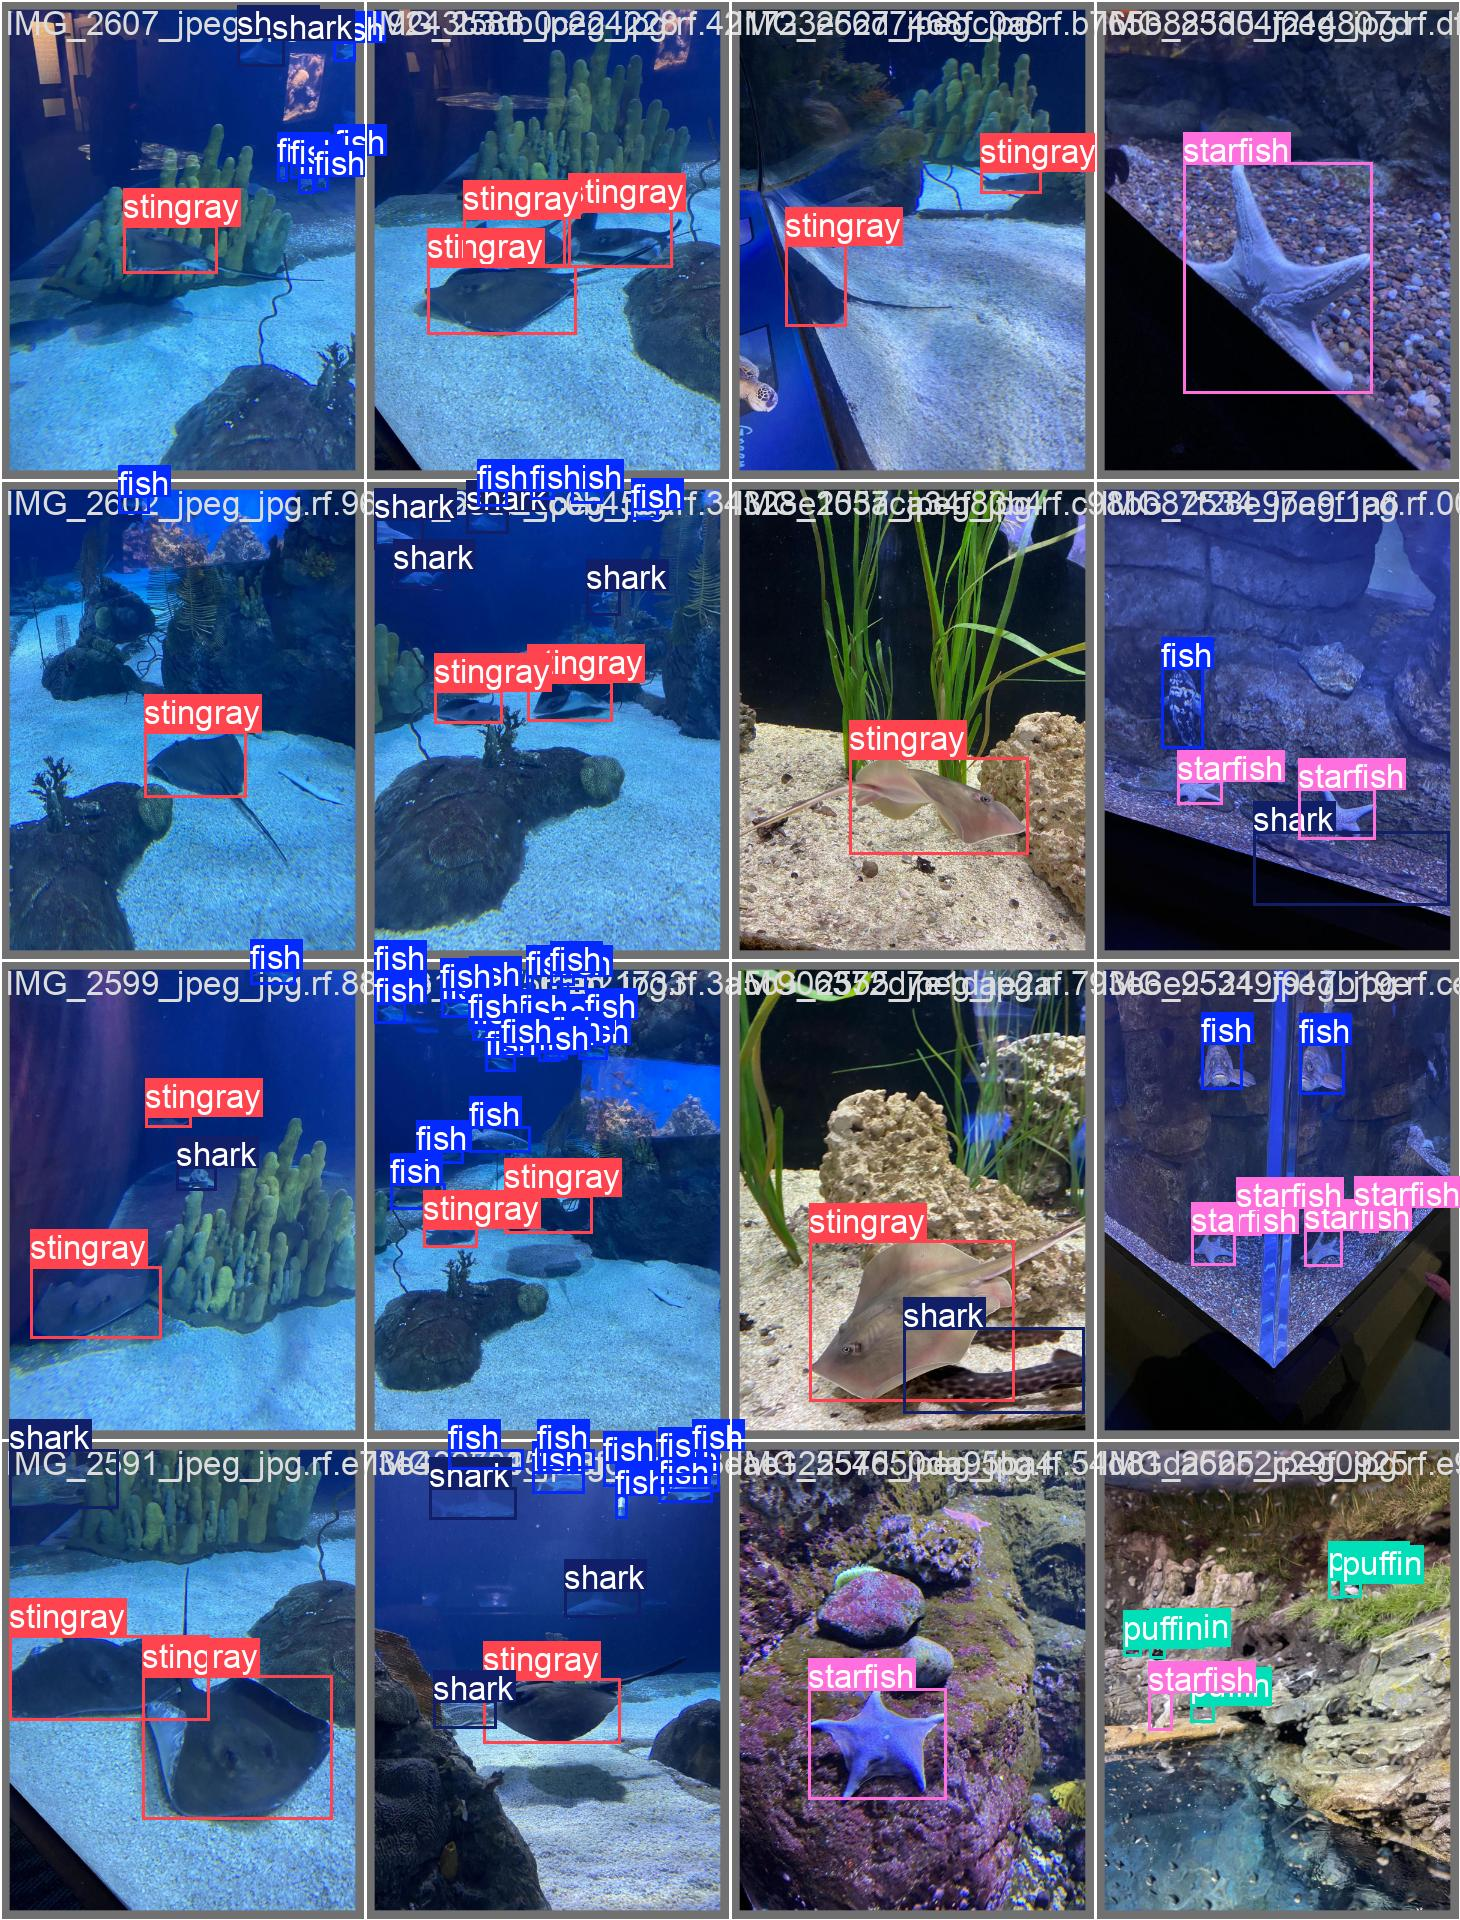

In [13]:
# 검증 이미지의 정답 상자
Image(filename=f'{run_dir}/val_batch1_labels.jpg', width=1000)

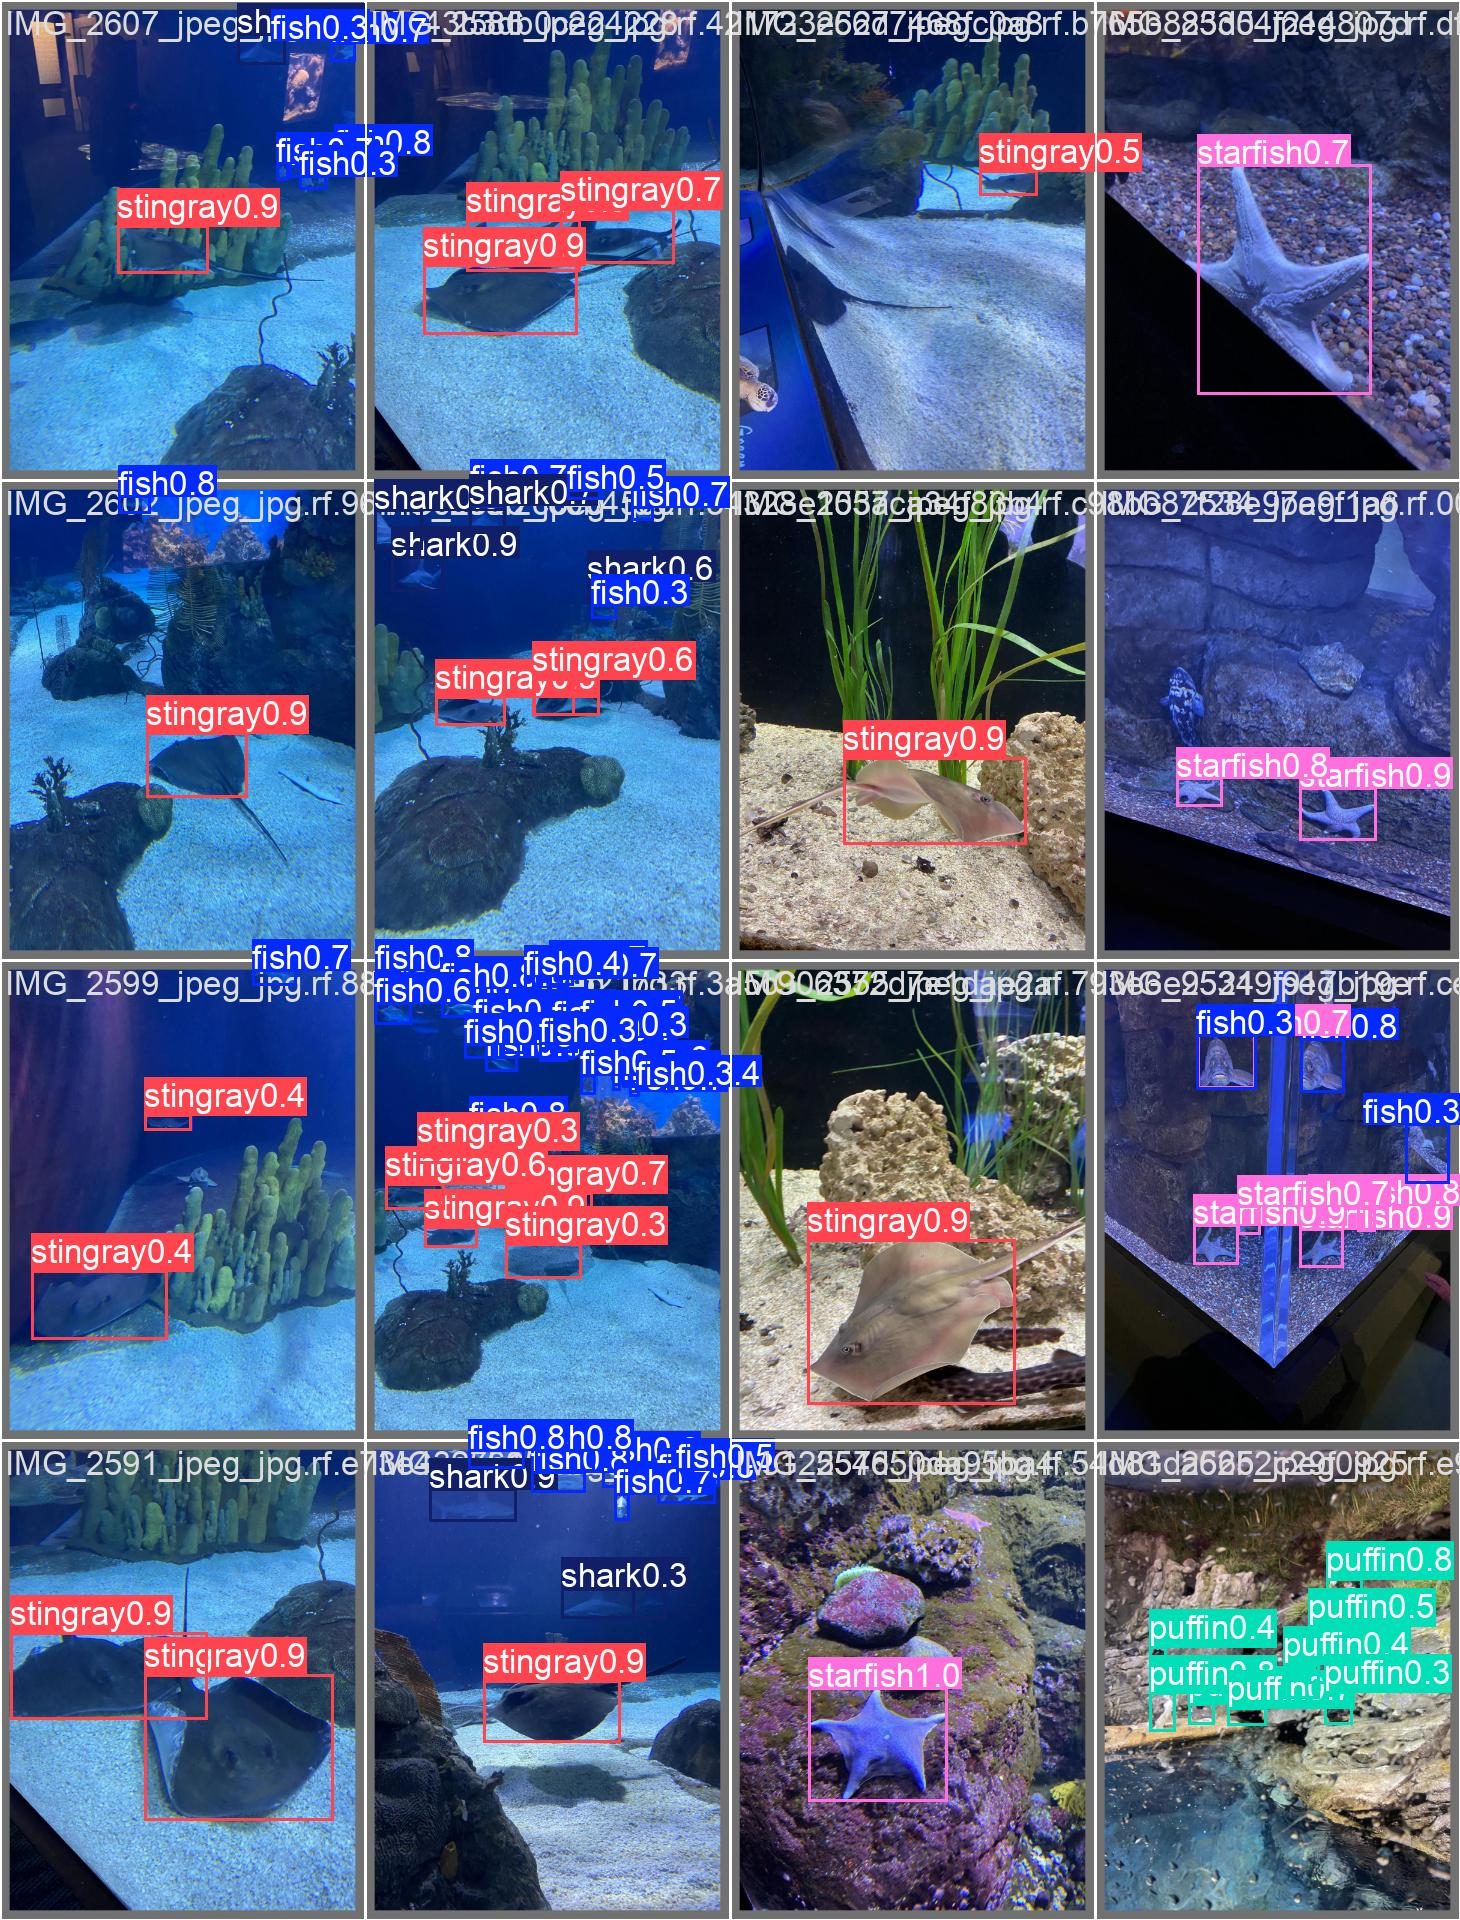

In [14]:
# 같은 검증 이미지에 대한 모델의 예측
Image(filename=f'{run_dir}/val_batch1_pred.jpg', width=1000)

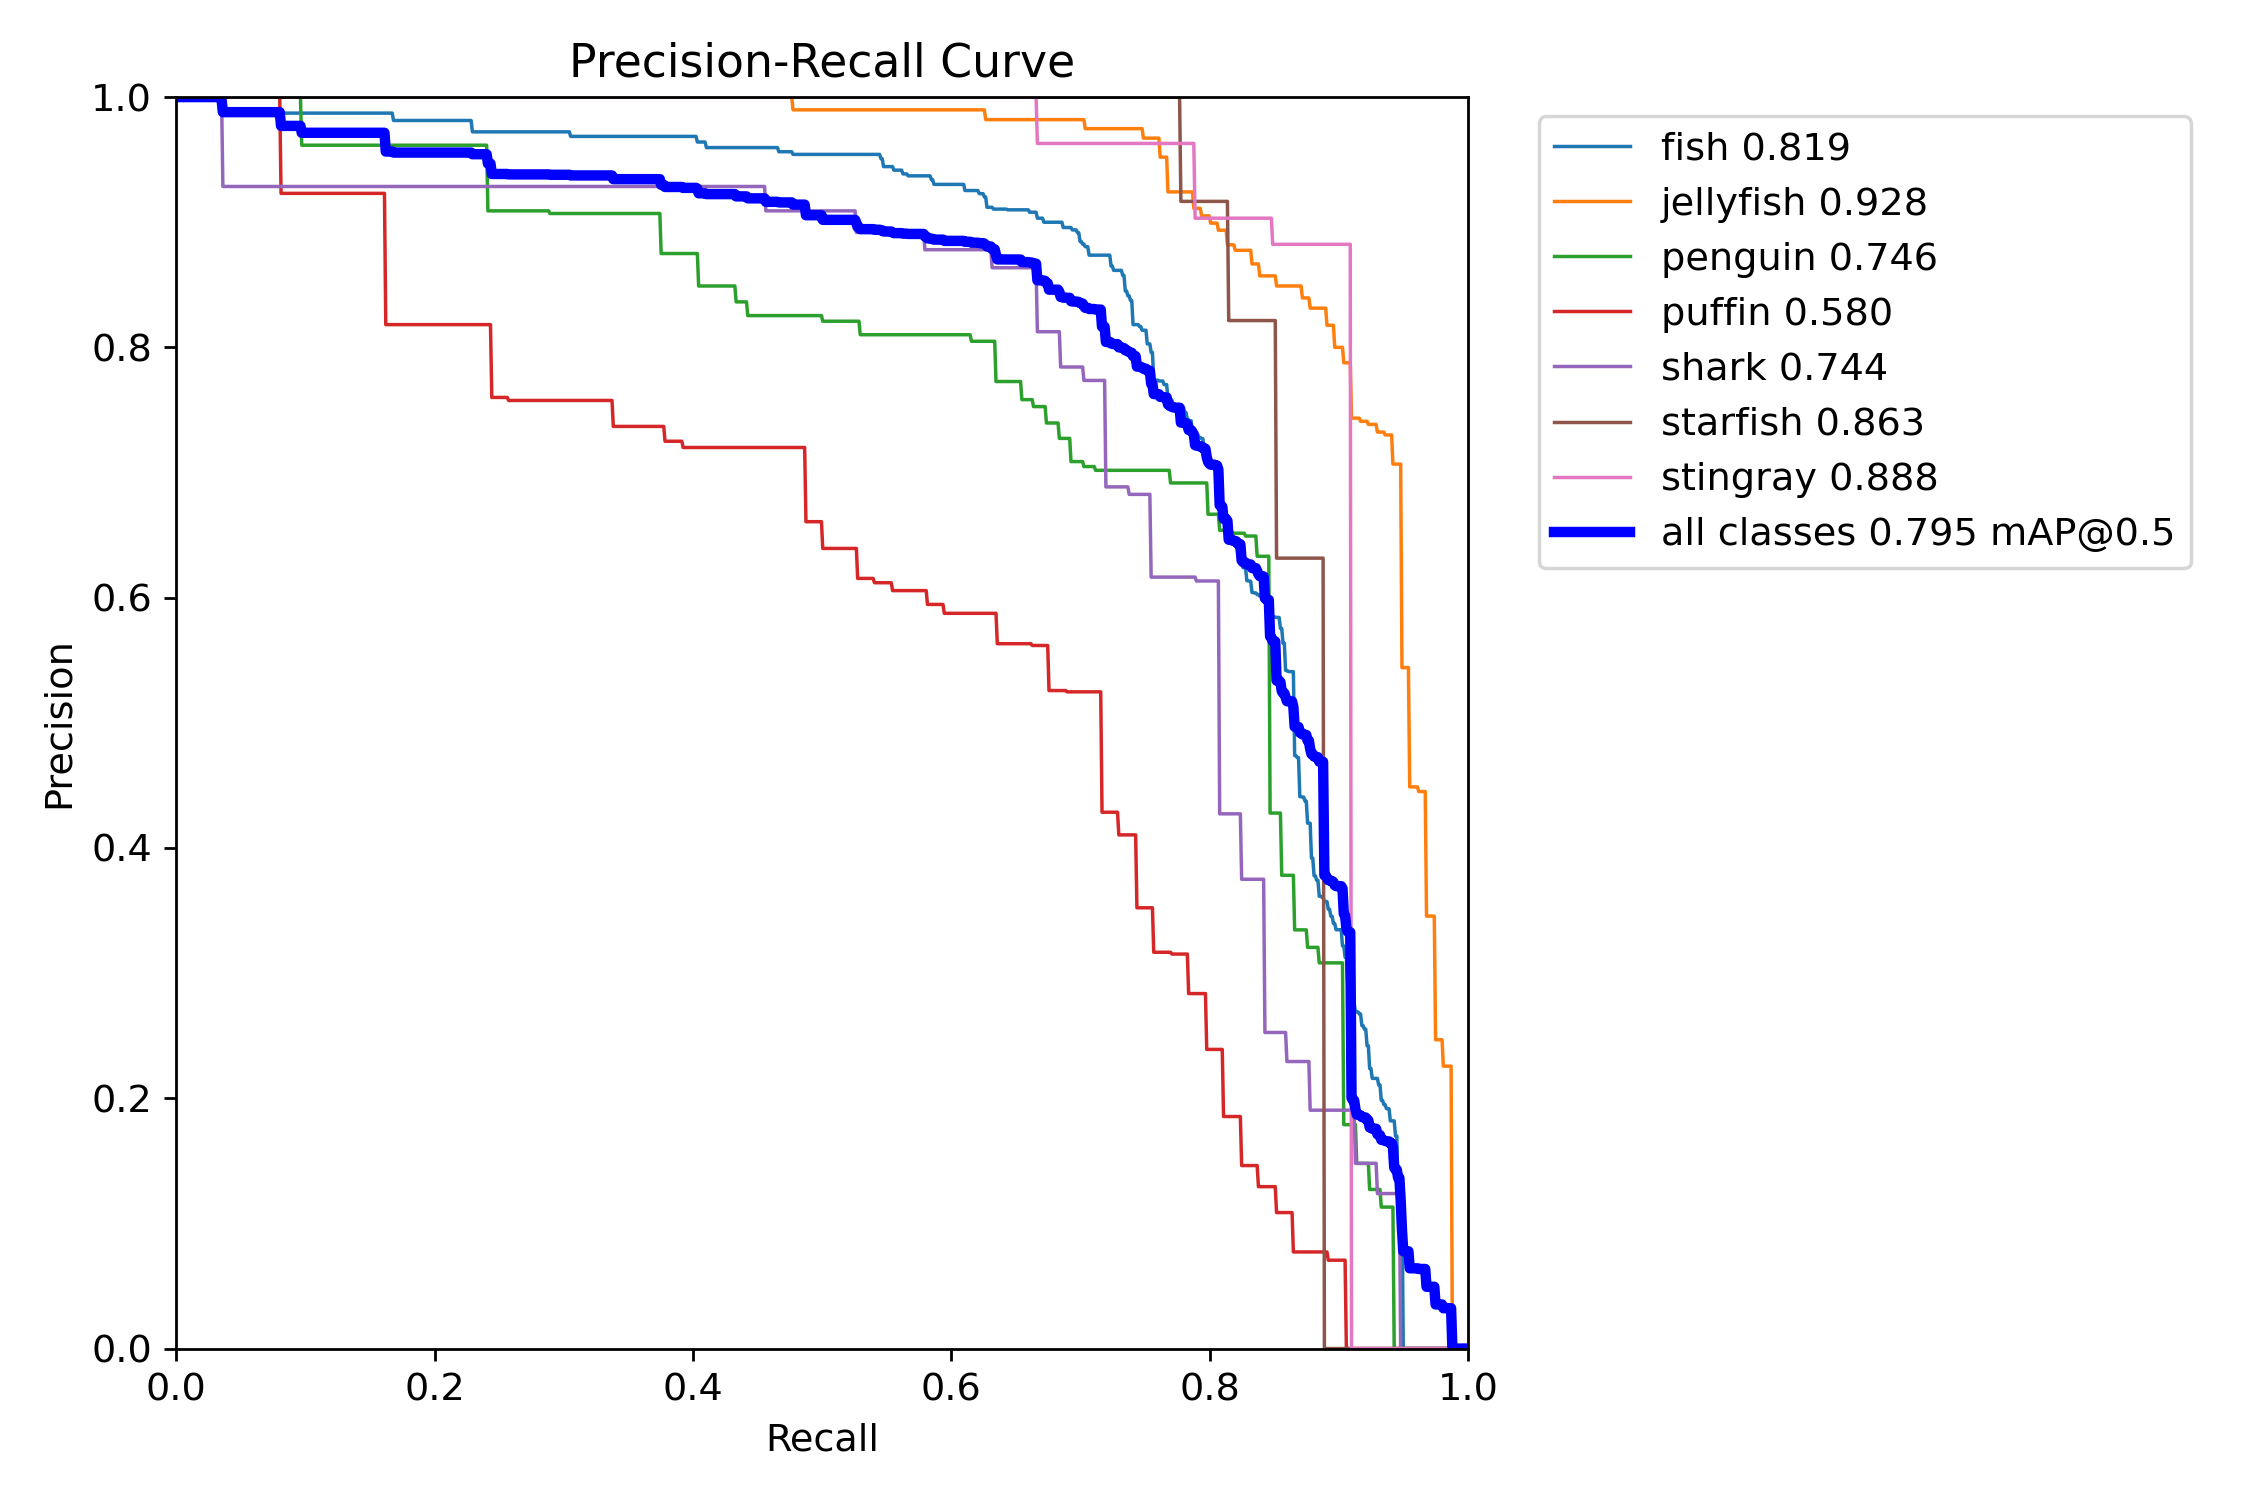

In [15]:
# 검증 데이터의 범주별 PR 곡선
Image(filename=glob.glob(f'{run_dir}/*PR_curve.png')[0], width=800)

In [16]:
# 가장 좋았던 가중치(best.pt)로 테스트 데이터를 평가한다.
best = YOLO(f'{run_dir}/weights/best.pt')
metrics = best.val(data=data_yaml, split='test', imgsz=640)
print('mAP50:', round(metrics.box.map50, 3), ' mAP50-95:', round(metrics.box.map, 3))

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,509 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 15.7±4.6 MB/s, size: 70.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/aquarium/test/labels... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63 504.8it/s 0.1s
val: New cache created: /content/aquarium/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2it/s 3.3s
                   all         63        584      0.855      0.708      0.814      0.509
                  fish         30        249      0.819      0.691      0.789      0.488
             jellyfish         11        154      0.817      0.818      0.874      0.565
               penguin

## 5. 검출

In [17]:
# test 이미지 전체에 대해 검출을 진행한다(신뢰도 0.4 이상만 상자로 남김).
res = best.predict('/content/aquarium/test/images', imgsz=640, conf=0.4, save=True, name='predict', exist_ok=True, verbose=False)
print(res[0].save_dir)

Results saved to /content/runs/detect/predict
/content/runs/detect/predict


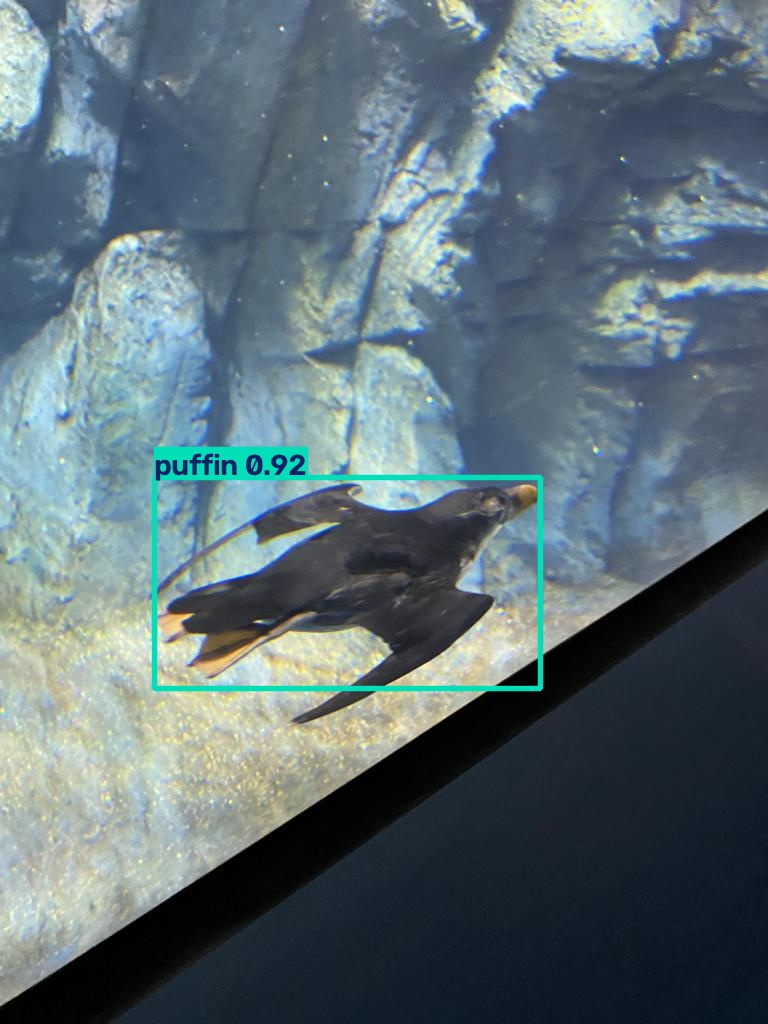

In [18]:
import random
# 검출 결과 사진 가운데 하나를 무작위로 골라 화면에 표시한다.
image_name = random.choice(glob.glob('/content/runs/detect/predict/*.jpg'))
display(Image(filename=image_name))

## 실습
1. **신뢰도 임계값**: `predict`의 `conf`를 0.1, 0.4, 0.7로 바꿔 같은 테스트 사진을 검출해 보세요. 상자 수와 틀린 상자는 어떻게 달라지나요? 6장의 임계값과 정밀도·재현율의 관계로 설명해 보세요.
2. **범주별 결과 읽기**: 테스트 데이터 결과표에서 mAP50이 가장 낮은 범주와 가장 높은 범주를 찾고, 그 범주의 P(정밀도)와 R(재현율)을 비교해 보세요. 왜 낮은지 학습 데이터의 물체 수(`labels.jpg`)와 연결해 보세요.

먼저 직접 해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [19]:
# 직접 작성해 보세요


### 예시 답안

In [20]:
# 1. 신뢰도 임계값 바꾸기 (같은 테스트 사진 세 장을 골라 비교)
sample = sorted(glob.glob('/content/aquarium/test/images/*.jpg'))[:3]
os.makedirs('/content/sample', exist_ok=True)
for p in sample:
    shutil.copy(p, '/content/sample/')
for conf in [0.1, 0.4, 0.7]:
    r = best.predict('/content/sample', imgsz=640, conf=conf, save=True, save_txt=True,
                     name=f'conf_{conf}', exist_ok=True, verbose=False)
    print(f"conf {conf}: 세 장의 상자 {sum(len(x.boxes) for x in r)}개, 그중 두 번째 사진(펭귄) {len(r[1].boxes)}개")

Results saved to /content/runs/detect/conf_0.1
3 labels saved to /content/runs/detect/conf_0.1/labels
conf 0.1: 세 장의 상자 47개, 그중 두 번째 사진(펭귄) 30개
Results saved to /content/runs/detect/conf_0.4
3 labels saved to /content/runs/detect/conf_0.4/labels
conf 0.4: 세 장의 상자 21개, 그중 두 번째 사진(펭귄) 14개
Results saved to /content/runs/detect/conf_0.7
3 labels saved to /content/runs/detect/conf_0.7/labels
conf 0.7: 세 장의 상자 8개, 그중 두 번째 사진(펭귄) 4개


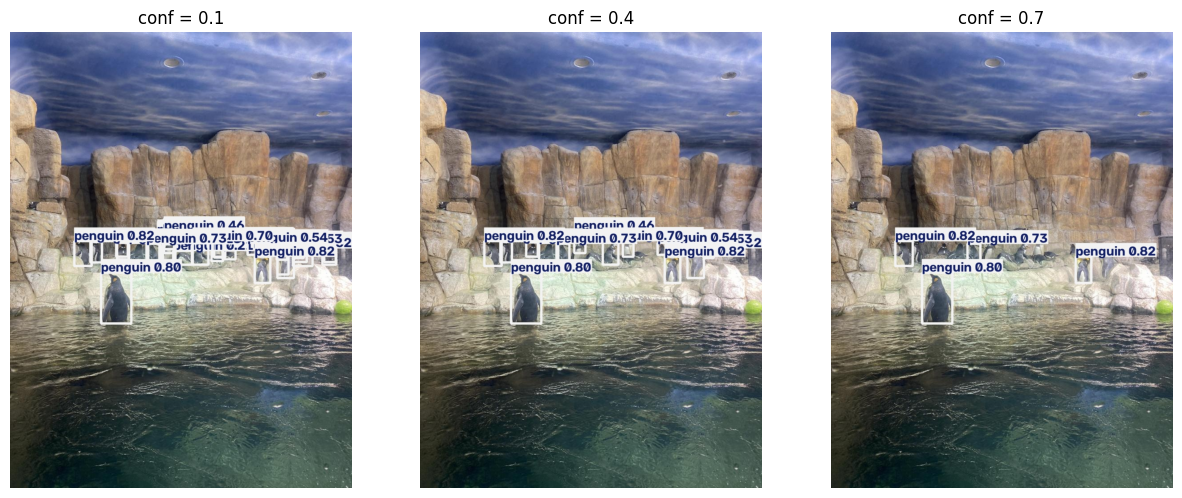

In [21]:
name = os.path.basename(sample[1])
plt.figure(figsize=(15, 6))
for k, conf in enumerate([0.1, 0.4, 0.7]):
    plt.subplot(1, 3, k + 1)
    plt.imshow(PILImage.open(f'/content/runs/detect/conf_{conf}/{name}'))
    plt.title(f'conf = {conf}'); plt.axis('off')
plt.show()

In [22]:
# 2. 학습 데이터의 범주별 물체 수
names = ['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']
cnt = Counter()
for f in glob.glob('/content/aquarium/train/labels/*.txt'):
    for line in open(f):
        cnt[int(line.split()[0])] += 1
for i, n in enumerate(names):
    print(f"{n:>10}: {cnt[i]:5d}개")

      fish:  1961개
 jellyfish:   385개
   penguin:   330개
    puffin:   175개
     shark:   259개
  starfish:    78개
  stingray:   136개
